# AG News: data preparation and exploration

Download AG News, inspect examples, and check class balance and data quality before training.

In [3]:
from datasets import load_dataset

ag_news = load_dataset("fancyzhx/ag_news")
ag_news

e:\VGTU\5 semester\Natural Language Processing\lab 4\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 120000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 7600
    })
})

In [4]:
print("Splits:", list(ag_news.keys()))
print("Columns:", ag_news["train"].column_names)
print("Features:", ag_news["train"].features)
print("Labels:", ag_news["train"].features["label"].names)

Splits: ['train', 'test']
Columns: ['text', 'label']
Features: {'text': Value('string'), 'label': ClassLabel(names=['World', 'Sports', 'Business', 'Sci/Tech'])}
Labels: ['World', 'Sports', 'Business', 'Sci/Tech']


In [5]:
for index, sample in enumerate(ag_news["train"].select(range(5)), start=1):
    print(f"Sample {index} | label={sample['label']}")
    print(sample["text"])
    print()

Sample 1 | label=2
Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling\band of ultra-cynics, are seeing green again.

Sample 2 | label=2
Carlyle Looks Toward Commercial Aerospace (Reuters) Reuters - Private investment firm Carlyle Group,\which has a reputation for making well-timed and occasionally\controversial plays in the defense industry, has quietly placed\its bets on another part of the market.

Sample 3 | label=2
Oil and Economy Cloud Stocks' Outlook (Reuters) Reuters - Soaring crude prices plus worries\about the economy and the outlook for earnings are expected to\hang over the stock market next week during the depth of the\summer doldrums.

Sample 4 | label=2
Iraq Halts Oil Exports from Main Southern Pipeline (Reuters) Reuters - Authorities have halted oil export\flows from the main pipeline in southern Iraq after\intelligence showed a rebel militia could strike\infrastructure, an oil official said on Saturday.

Sample 5 | label=2

## Dataset statistics

Statistics are reported separately for training and test data.

In [6]:
import pandas as pd
import matplotlib.pyplot as plt

label_names = ag_news['train'].features['label'].names
frames = {split: dataset.to_pandas() for split, dataset in ag_news.items()}
class_counts = pd.DataFrame({
    split: frame['label'].value_counts().reindex(range(len(label_names)), fill_value=0)
    for split, frame in frames.items()
})
class_counts.index = label_names
class_counts.index.name = 'class'
display(class_counts)

,train,test
class,,
World,30000,1900
Sports,30000,1900
Business,30000,1900
Sci/Tech,30000,1900


In [7]:
length_rows = []
for split, frame in frames.items():
    text = frame['text'].fillna('')
    for unit, lengths in [('characters', text.str.len()), ('words', text.str.split().str.len())]:
        length_rows.append({
            'split': split, 'unit': unit, 'min': lengths.min(),
            'median': lengths.median(), 'mean': lengths.mean(),
            'p95': lengths.quantile(0.95), 'max': lengths.max(),
        })
length_stats = pd.DataFrame(length_rows).set_index(['split', 'unit'])
display(length_stats.round(1))

min  median   mean    p95   max
split unit                                       
train characters  100   232.0  236.5  343.0  1012
      words         8    37.0   37.8   53.0   177
test  characters  100   231.0  235.3  336.0   892
      words        11    37.0   37.7   52.0   137

In [8]:
quality_rows = []
for split, frame in frames.items():
    text = frame['text']
    quality_rows.append({
        'split': split, 'missing_text': text.isna().sum(),
        'blank_text': text.fillna('').str.strip().eq('').sum(),
        'missing_label': frame['label'].isna().sum(),
        'duplicate_text': text.duplicated().sum(),
        'duplicate_rows': frame.duplicated().sum(),
    })
quality = pd.DataFrame(quality_rows).set_index('split')
display(quality)
print('Texts shared between train and test:', len(set(frames['train']['text']) & set(frames['test']['text'])))

,missing_text,blank_text,missing_label,duplicate_text,duplicate_rows
split,,,,,
train,0,0,0,0,0
test,0,0,0,0,0


Texts shared between train and test: 0


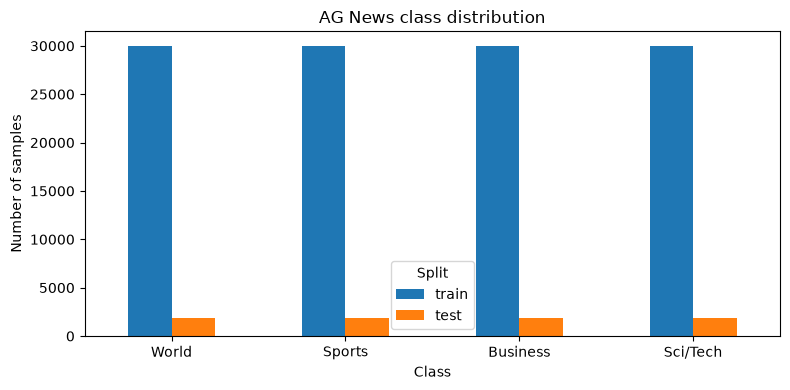

In [9]:
ax = class_counts.plot.bar(figsize=(8, 4), rot=0)
ax.set_title('AG News class distribution')
ax.set_xlabel('Class')
ax.set_ylabel('Number of samples')
ax.legend(title='Split')
plt.tight_layout()
plt.show()